In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import random

In [2]:
df = pd.read_csv("ramen-ratings.csv")
def safe_float(string):
    try:
        return float(string)
    except (TypeError, ValueError):
        return None
df["Stars"] = df["Stars"].map(lambda x: safe_float(x))
df

,Review #,Brand,Variety,Style,Country,Stars,Top Ten
0,2580,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75,NaN
1,2579,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1.00,NaN
2,2578,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25,NaN
3,2577,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75,NaN
4,2576,Ching's Secret,Singapore Curry,Pack,India,3.75,NaN
...,...,...,...,...,...,...,...
2575,5,Vifon,"Hu Tiu Nam Vang [""Phnom Penh"" style] Asian Sty...",Bowl,Vietnam,3.50,NaN
2576,4,Wai Wai,Oriental Style Instant Noodles,Pack,Thailand,1.00,NaN
2577,3,Wai Wai,Tom Yum Shrimp,Pack,Thailand,2.00,NaN
2578,2,Wai Wai,Tom Yum Chili Flavor,Pack,Thailand,2.00,NaN


In [3]:
type(df["Stars"][0])

numpy.float64

In [4]:
df.drop(df[df.Stars.map(type) == str].index)

,Review #,Brand,Variety,Style,Country,Stars,Top Ten
0,2580,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75,NaN
1,2579,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1.00,NaN
2,2578,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25,NaN
3,2577,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75,NaN
4,2576,Ching's Secret,Singapore Curry,Pack,India,3.75,NaN
...,...,...,...,...,...,...,...
2575,5,Vifon,"Hu Tiu Nam Vang [""Phnom Penh"" style] Asian Sty...",Bowl,Vietnam,3.50,NaN
2576,4,Wai Wai,Oriental Style Instant Noodles,Pack,Thailand,1.00,NaN
2577,3,Wai Wai,Tom Yum Shrimp,Pack,Thailand,2.00,NaN
2578,2,Wai Wai,Tom Yum Chili Flavor,Pack,Thailand,2.00,NaN


                  average_stars
Brand                          
1 To 3 Noodles         4.000000
7 Select               3.750000
7 Select/Nissin        3.500000
A-One                  2.750000
A-Sha Dry Noodle       4.067308
...                         ...
Yum Yum                3.750000
Yum-Mie                3.500000
Zow Zow                3.750000
iMee                   3.500000
iNoodle                3.000000

[355 rows x 1 columns]


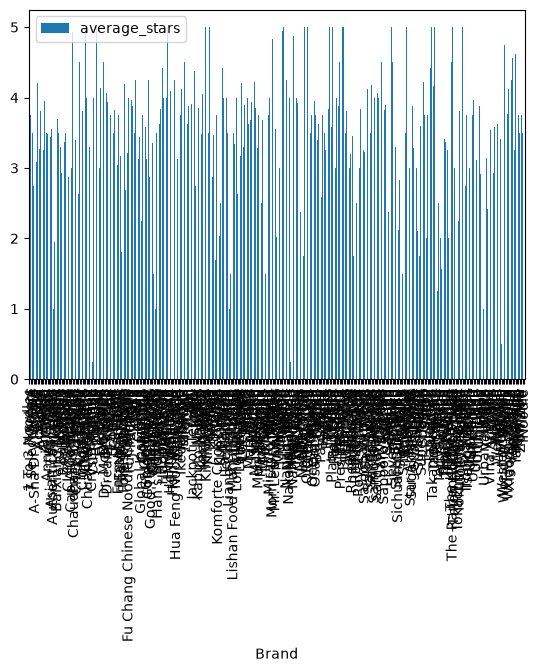

      Review #           Brand  \
0         2580       New Touch   
1         2579        Just Way   
2         2578          Nissin   
3         2577         Wei Lih   
4         2576  Ching's Secret   
...        ...             ...   
2575         5           Vifon   
2576         4         Wai Wai   
2577         3         Wai Wai   
2578         2         Wai Wai   
2579         1        Westbrae   

                                                Variety Style   Country Stars  \
0                             T's Restaurant Tantanmen    Cup     Japan  3.75   
1     Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...  Pack    Taiwan     1   
2                         Cup Noodles Chicken Vegetable   Cup       USA  2.25   
3                         GGE Ramen Snack Tomato Flavor  Pack    Taiwan  2.75   
4                                       Singapore Curry  Pack     India  3.75   
...                                                 ...   ...       ...   ...   
2575  Hu Tiu Nam Vang ["

KeyError: False

In [61]:
grouped = df.groupby("Brand").agg(average_stars=("Stars", "mean"))
print(grouped)
grouped.plot(kind="bar")
plt.show()
show_bar_chart_stars_per_manufacturer(ramen_data)

In [19]:
def show_histogram_of_ramen_scores(df):
    """
    Create a histogram to show the distribution of numbers of stars given to ramen.
    """
    # Use group by to collect them together and size to get the count
    print(df)
    grouped = df.groupby("Stars").size()
    grouped.plot(kind="hist")
    plt.show()

In [ ]:
def menu():
    """Displays menu and allows user to enter choice to be returned to main - if you add more, remember to add them to the 'while choice not in' line!"""
    print("~ ramen rating database ~")
    print("1 - See distribution of scores")
    print("2 - see average score per manufacturer")
    print("3 - see average score per country")
    print("4 - Get a breakdown of a specific country")
    print("5 - See the top ten ramens")
    print("6 - See a random Ramen")
    choice = ""
    while choice not in ["1", "2", "3", "4", "5", "6", "Q"]:
        choice = input("Pick an option: ").upper()
    return choice

In [ ]:
while True:
    choice = menu()
    match choice:
        case "1":
            show_histogram_of_ramen_scores(ramen_data)
        case "2":
            show_bar_chart_stars_per_manufacturer(ramen_data)
        case "3":
            show_bar_chart_stars_per_country(ramen_data)
        case "4":
            country = input("Enter country: ").title()
            find_best_per_country(ramen_data, country)
            find_worst_per_country(ramen_data, country)
            show_piechart_of_manufacturers_by_country(ramen_data, country)
        case "5":
            show_top_ten(ramen_data)
        case "6":
            random_ramen_review(ramen_data)
        case "Q":
            break